In [1]:
import json
import os
import re

import numpy as np
import matplotlib.pyplot as plt

In [2]:
STEPS = [128, 256, 512, 1000, 2000, 3000, 6000, 12000, 16000, 32000, 48000, 79000]

def lr_scheduler(step, total_steps=143000):
    if step < total_steps * 0.01:
        return step / (total_steps * 0.01)
    progress = (step - total_steps * 0.01) / (total_steps * 0.99)
    return 0.5 * (1.0 + np.cos(np.pi * progress)) * 0.9 + 0.1

cache_path = '../cache/lrs_cache.npy'
if os.path.exists(cache_path):
    lrs = np.load(cache_path)
else:
    lrs = np.array([lr_scheduler(s) for s in range(1, 143001)])
    np.save(cache_path, lrs)

# tau[i] = integral of lr from step 1 to STEPS[i]
cumsum = np.cumsum(lrs)
tau = cumsum[np.array(STEPS) - 1]

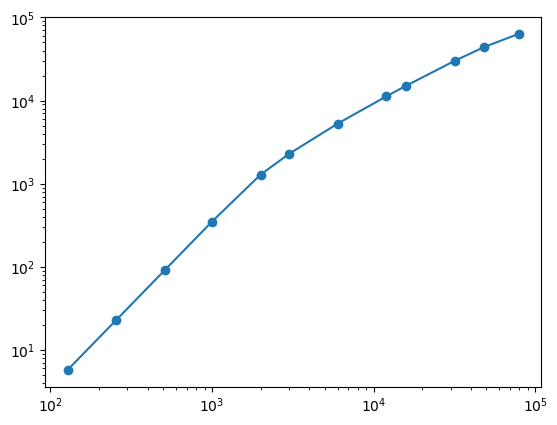

In [3]:
plt.plot(STEPS, tau, marker='o')
plt.xscale('log')
plt.yscale('log')

In [4]:
# Training loss — second run only.
# The first run was killed and the second was appended, so steps reset.
# Find the last index where step goes backward; everything after is the final run.
with open('../checkpoints/mse_1/metrics.jsonl') as f:
    train_rows = [json.loads(line) for line in f]

restart_idx = 0
for i in range(1, len(train_rows)):
    if train_rows[i]['step'] < train_rows[i-1]['step']:
        restart_idx = i
train_rows = train_rows[restart_idx:]

train_steps = np.array([r['step'] for r in train_rows])
train_loss  = np.array([r['loss'] for r in train_rows])
train_kl = np.array([r['eval_kl'] for r in train_rows])
train_tau = cumsum[train_steps - 1]

# Eval loss — filter eval.jsonl for kl_1 rows only
with open('../results/eval.jsonl') as f:
    eval_rows = [json.loads(line) for line in f if 'mse_1/' in line]

eval_steps = np.array([int(re.search(r'step_(\d+)', r['model']).group(1))
                       for r in eval_rows])
eval_loss  = np.array([r['avg_loss'] for r in eval_rows])

order = np.argsort(eval_steps)
eval_steps, eval_loss = eval_steps[order], eval_loss[order]

# logit std and entropy
with open('../results/eval_stats.jsonl') as f:
      all_stats = [json.loads(line) for line in f]
stats_rows = [r for r in all_stats if 'mse_1/' in r['model']]
teacher_rows = [r for r in all_stats if 'pythia-160m' in r['model'] and 1.0 == r['temperature']]

logit_stds = np.array([r['logit_std'] for r in stats_rows])
entropies = np.array([r['entropy'] for r in stats_rows])

t_logit_std = np.array([r['logit_std'] for r in teacher_rows])
t_entropy = np.array([r['entropy'] for r in teacher_rows])

Estimated decay rate: -3.549825774572772e-06


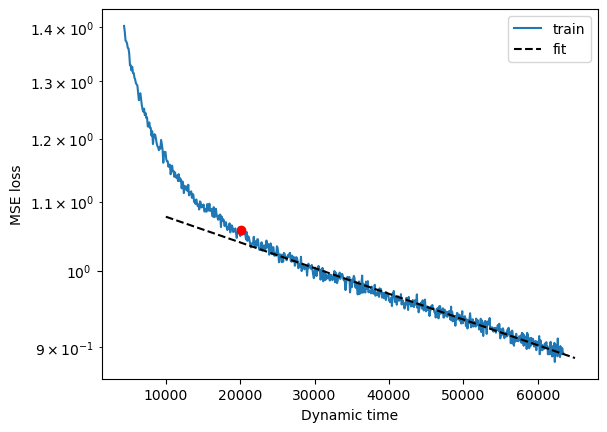

In [5]:
decay_rate, log_coeff = np.polyfit(train_tau[210:], np.log(train_loss[210:]), 1)
plt.plot(train_tau[50:], train_loss[50:], '-', label='train')
plt.plot(train_tau[210], train_loss[210], 'or')
plot_x = np.linspace(10000, 65000, 100)
plt.plot(plot_x, np.exp(log_coeff + plot_x * decay_rate), 'k--', label='fit')
print(f'Estimated decay rate: {decay_rate}')
#plt.plot(tau, eval_loss, 'o', label='eval')
plt.xlabel('Dynamic time')
plt.ylabel('MSE loss')
#plt.xscale('log')
plt.yscale('log')
plt.legend()

In [6]:
from scipy import optimize
def residuals(x, c_l, alpha_l, L0):
    return np.log((c_l / (x ** alpha_l) + L0))
'''
fitout = optimize.curve_fit(residuals, tau[2:], 
                            np.log(eval_loss[2:]), 
                            maxfev=100000, p0=[10,0.3,eval_loss[-1]],
                                    bounds = ([0,0,0], [np.inf,np.inf,eval_loss[-1]]))
'''
fitout = optimize.curve_fit(residuals, train_tau[50:], 
                            np.log(train_loss[50:]), 
                            maxfev=100000, p0=[10,0.3,train_loss[-1]],
                                    bounds = ([0,0,0], [np.inf,np.inf,train_loss[-1]]))

c_tau = fitout[0][0]
alpha_tau = fitout[0][1]
alpha_tau_stderr = np.sqrt(np.diag(fitout[1]))[1]
L0_tau = fitout[0][2]

In [7]:
tau[-4]

15171.849474843286

In [8]:
train_tau[50], train_tau[200]

(4383.674212814927, 19147.18132195147)

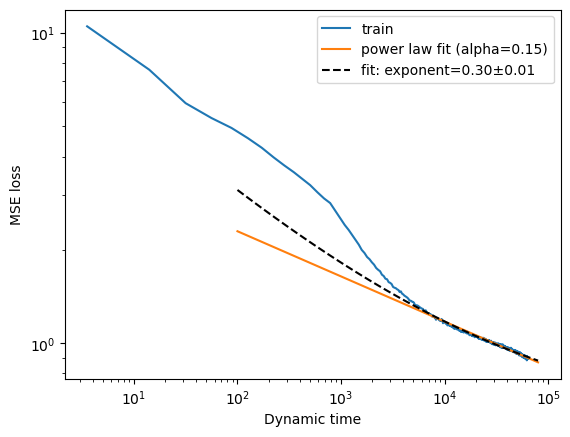

In [9]:
n_alpha_tau, n_c_tau = np.polyfit(np.log(train_tau[50:]), np.log(train_loss[50:]), 1)
plt.plot(train_tau, train_loss, '-', label='train')
#plt.plot(tau, eval_loss, 'o', label='eval')
plot_x = np.logspace(np.log10(100), np.log10(80000), 100)
plt.plot(plot_x, np.exp(n_c_tau) * plot_x ** n_alpha_tau, label=f'power law fit (alpha={-n_alpha_tau:.2f})')
plt.plot(plot_x, c_tau / (plot_x ** alpha_tau) + L0_tau, 'k--', label=f'fit: exponent={alpha_tau:.2f}±{alpha_tau_stderr:.2f}')
plt.xlabel('Dynamic time')
plt.ylabel('MSE loss')
plt.xscale('log')
plt.yscale('log')
plt.legend()

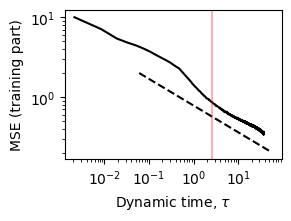

In [16]:
#n_alpha_tau, n_c_tau = np.polyfit(np.log(train_tau[50:]), np.log(train_loss[50:]), 1)
lr = 6e-4
plt.figure(figsize=(2.8,2.1), constrained_layout=True)
plt.plot(train_tau*lr, train_loss - L0_tau, 'k-')
#plt.plot(tau, eval_loss, 'o', label='eval')
#plot_x = np.logspace(np.log10(100*lr), np.log10(80000*lr), 100)
plt.plot([1e+2 * lr, 9.5e+4 * lr], [2, 2 / 9.5e+2 ** (1/3)], 'k--')
plt.axvline(4383*lr, color='r', linestyle='-', alpha = 0.3)
#plt.plot(plot_x, np.exp(n_c_tau) * plot_x ** n_alpha_tau, label=f'power law fit (alpha={-n_alpha_tau:.2f})')
#plt.plot(plot_x, c_tau / (plot_x ** alpha_tau), 'k--', label=f'fit: exponent={alpha_tau:.2f}±{alpha_tau_stderr:.2f}')
plt.xlabel(r'Dynamic time, $\tau$')
plt.ylabel('MSE (training part)')
plt.xscale('log')
plt.yscale('log')
#plt.legend()
plt.savefig('../figures/mse_1_loss.pdf')

In [9]:
fitout = optimize.curve_fit(residuals, tau[4:], 
                            np.log(eval_loss[4:]), 
                            maxfev=100000, p0=[10,0.3,eval_loss[-1]],
                                    bounds = ([0,0,0], [np.inf,np.inf,eval_loss[-1]]))
'''
fitout = optimize.curve_fit(residuals, train_tau[120:], 
                            np.log(train_kl[120:]), 
                            maxfev=100000, p0=[10,0.3,eval_loss[-1]],
                                    bounds = ([0,0,0], [np.inf,np.inf,eval_loss[-1]]))
'''
c_tau = fitout[0][0]
alpha_tau = fitout[0][1]
alpha_tau_stderr = np.sqrt(np.diag(fitout[1]))[1]
L0_tau = fitout[0][2]

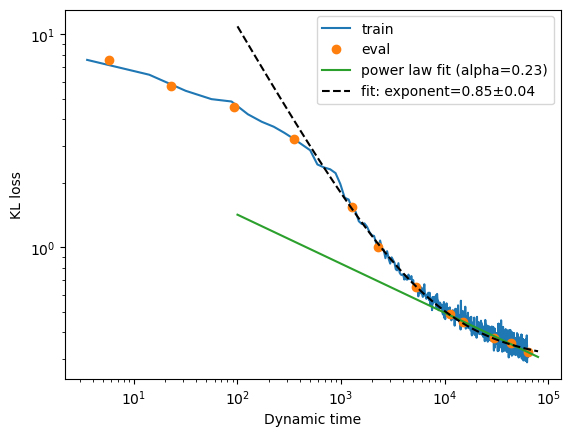

In [10]:
n_alpha_tau, n_c_tau = np.polyfit(np.log(tau[7:]), np.log(eval_loss[7:]), 1)
plt.plot(train_tau, train_kl, '-', label='train')
plt.plot(tau, eval_loss, 'o', label='eval')
plot_x = np.logspace(np.log10(100), np.log10(80000), 100)
plt.plot(plot_x, np.exp(n_c_tau) * plot_x ** n_alpha_tau, label=f'power law fit (alpha={-n_alpha_tau:.2f})')
plt.plot(plot_x, c_tau / (plot_x ** alpha_tau) + L0_tau, 'k--', label=f'fit: exponent={alpha_tau:.2f}±{alpha_tau_stderr:.2f}')
plt.xlabel('Dynamic time')
plt.ylabel('KL loss')
plt.xscale('log')
plt.yscale('log')
plt.legend()

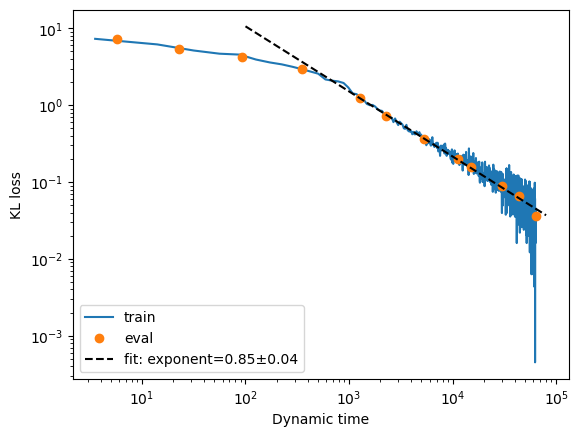

In [11]:
plt.plot(train_tau, train_kl - L0_tau, '-', label='train')
plt.plot(tau, eval_loss - L0_tau, 'o', label='eval')
plot_x = np.logspace(np.log10(100), np.log10(80000), 100)
#plt.plot(plot_x, np.exp(n_c_tau) * plot_x ** n_alpha_tau, label=f'power law fit (alpha={-n_alpha_tau:.2f})')
plt.plot(plot_x, c_tau / (plot_x ** alpha_tau), 'k--', label=f'fit: exponent={alpha_tau:.2f}±{alpha_tau_stderr:.2f}')
plt.xlabel('Dynamic time')
plt.ylabel('KL loss')
plt.xscale('log')
plt.yscale('log')
plt.legend()

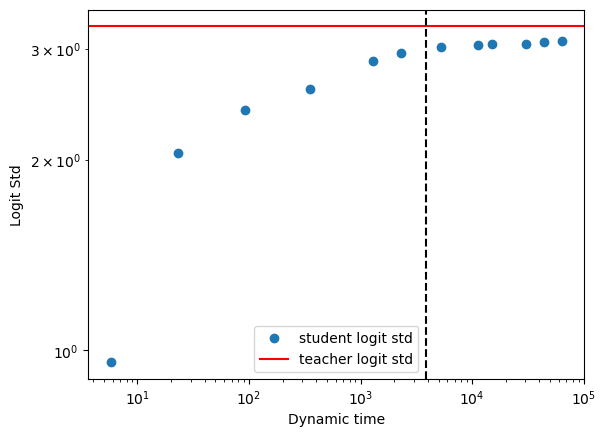

In [20]:
plt.plot(tau, logit_stds, 'o', label='student logit std')
#plt.plot([10, 1e+3], [1, 1e+2 ** (1/3)], '--')
plt.axhline(t_logit_std[0], color='r', label='teacher logit std')
plt.axvline(train_tau[45], color='k', linestyle='--')
plt.xlabel('Dynamic time')
plt.ylabel('Logit Std')
plt.xscale('log')
plt.yscale('log')
plt.legend()

In [13]:
logit_stds

array([0.957158, 2.053637, 2.400494, 2.589938, 2.865187, 2.949638,
       3.017138, 3.04192 , 3.049778, 3.054698, 3.071914, 3.089031])

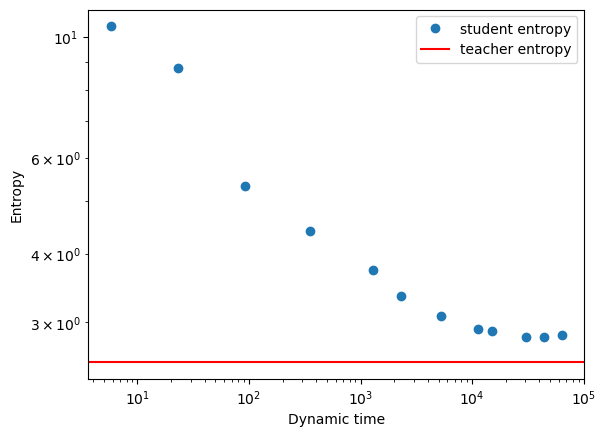

In [16]:
plt.plot(tau, entropies, 'o', label='student entropy')
plt.axhline(t_entropy[0], color='r', label='teacher entropy')
plt.xlabel('Dynamic time')
plt.ylabel('Entropy')
plt.xscale('log')
plt.yscale('log')
plt.legend()

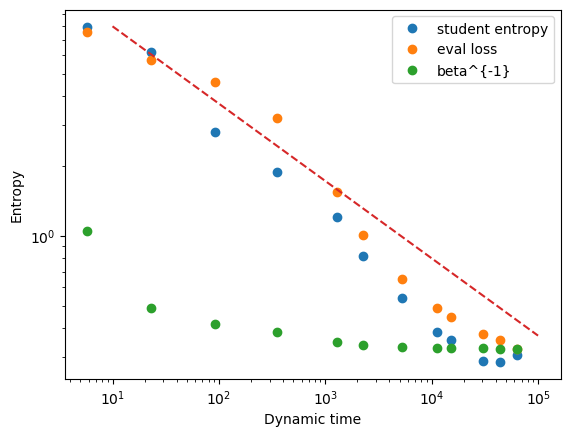

In [19]:
plt.plot(tau, entropies - t_entropy[0], 'o', label='student entropy')
plt.plot(tau, (eval_loss), 'o', label='eval loss')
plt.plot(tau, 1 / logit_stds, 'o', label='beta^{-1}')
plt.plot([1e+1,1e+5], [8, 8 / 1e+4 ** (1/3)], '--') # H = c_1 + 2 c_2 \beta^{-1}; L = c_2 \beta^{-1}
#plt.axhline(t_entropy[0], color='r', label='teacher entropy')
plt.xlabel('Dynamic time')
plt.ylabel('Entropy')
plt.xscale('log')
plt.yscale('log')
plt.legend()